# Bedside Monitor Data Collection via MQTT

This notebook shows how to collect a live stream of patient vital signs from bedside
monitors using MQTT, the messaging protocol most medical-device gateways speak.

## Overview

A modern ward publishes continuously. Each bedside monitor sends:
- **Vitals feed**: heart rate, blood pressure, oxygen saturation, respiratory rate and temperature, every few minutes
- **Status feed**: device state, lead quality, battery and active alarms

## Why this notebook uses a simulator

Every other streaming tutorial you have seen probably connects to a public test broker.
There is no public equivalent for patient data, and there should not be: continuous
vitals are among the most sensitive data a hospital holds.

So this notebook runs against `bedside_monitor_simulator.py`, which publishes a
simulated ward. The simulator deliberately mirrors the `paho-mqtt` client API, so
**the code you write here is the code you would write against a real gateway**. To point
it at a real one, swap `SimulatedMonitorClient` for `paho.mqtt.client.Client` and
change the topic strings. Nothing else in this notebook changes.

## Connection details

| Setting | Simulated ward | A real deployment |
|---|---|---|
| Host | in-process | the device gateway, usually inside the hospital network |
| Port | n/a | 1883 (plain) or 8883 (TLS) |
| Auth | none | client certificate or username and password, always |
| Encryption | n/a | TLS, mandatory for any real patient data |

> **About the data.** Every patient here is simulated from published physiological
> reference ranges. No real or identifiable patient data is used.

> **About security.** A real vitals feed is protected health information. It must be
> encrypted in transit, access-controlled, and audited. The simulator skips all of that
> precisely because it is not real.


## 1. Setup and Dependencies

In [1]:
# paho-mqtt is already a project dependency and is what you would use against a
# real broker. The simulator mirrors its API.
import json
import time
import threading
from datetime import datetime
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import sys
sys.path.insert(0, '../..')
from bedside_monitor_simulator import SimulatedMonitorClient, load_sample_vitals

print("Libraries loaded.")
print("Simulated ward client ready.")


Libraries loaded.
Simulated ward client ready.


## 2. Connection Configuration

Topics follow the shape a device gateway typically uses: one branch per bed, with a
separate leaf for each kind of message. The `+` wildcard matches exactly one level, so
`ward/bed/+/vitals` subscribes to the vitals feed of every bed at once.


In [2]:
# Connection configuration
BROKER_HOST = "simulated"     # a real deployment: the device gateway hostname
BROKER_PORT = 1883            # a real deployment: 8883 with TLS
NUM_BEDS = 4                  # how many bedside monitors are publishing

# Topic structure
TOPIC_VITALS = "ward/bed/+/vitals"    # + matches any single bed id
TOPIC_STATUS = "ward/bed/+/status"

# The simulator runs faster than real time so a whole stay can be collected in
# seconds. At speedup=3000, one wall-clock second carries about 50 minutes of
# patient time, so a short run still covers most of a shift per bed.
SPEEDUP = 3000

print(f"Broker:   {BROKER_HOST}:{BROKER_PORT}")
print(f"Beds:     {NUM_BEDS}")
print(f"Topics:   {TOPIC_VITALS}")
print(f"          {TOPIC_STATUS}")
print(f"Speedup:  {SPEEDUP}x real time ({SPEEDUP * 5 / 60:.0f} min of patient time per second)")


Broker:   simulated:1883
Beds:     4
Topics:   ward/bed/+/vitals
          ward/bed/+/status
Speedup:  3000x real time (250 min of patient time per second)


## 3. The Vitals Collector

This class is the heart of the notebook. It connects, subscribes, and buffers every
message that arrives. The callback structure (`on_connect`, `on_message`) is the MQTT
convention and is identical against a real broker.


In [3]:
class VitalsCollector:
    """Collects streamed bedside-monitor messages into in-memory buffers.

    Mirrors how you would collect from a real MQTT device gateway: subscribe to the
    topics you care about, accumulate messages as they arrive on the network thread,
    then convert the buffers to DataFrames once collection stops.
    """

    def __init__(self, beds=NUM_BEDS, speedup=SPEEDUP, hours=24.0):
        self.vitals_buffer = []
        self.status_buffer = []
        self.message_counts = defaultdict(int)
        self.connected = False
        self._lock = threading.Lock()

        # Swap this line for paho.mqtt.client.Client() to use a real broker.
        self.client = SimulatedMonitorClient(beds=beds, speedup=speedup, hours=hours)
        self.client.on_connect = self._on_connect
        self.client.on_message = self._on_message
        self.client.on_disconnect = self._on_disconnect

    # -- MQTT callbacks ---------------------------------------------------
    def _on_connect(self, client, userdata, flags, rc):
        """Called once the broker accepts the connection. rc=0 means success."""
        if rc == 0:
            self.connected = True
            print(f"Connected to {BROKER_HOST}:{BROKER_PORT}")
        else:
            print(f"Connection failed with code {rc}")

    def _on_disconnect(self, client, userdata, rc):
        self.connected = False
        print("Disconnected.")

    def _on_message(self, client, userdata, msg):
        """Called for every message on a subscribed topic."""
        try:
            payload = json.loads(msg.payload.decode("utf-8"))
        except (json.JSONDecodeError, UnicodeDecodeError) as exc:
            # A real feed will occasionally deliver a malformed message. Never let
            # one bad payload kill the collector.
            print(f"Skipping unparseable message on {msg.topic}: {exc}")
            return

        with self._lock:
            self.message_counts[msg.topic] += 1
            if msg.topic.endswith("/vitals"):
                self.vitals_buffer.append(payload)
            elif msg.topic.endswith("/status"):
                self.status_buffer.append(payload)

    # -- control ----------------------------------------------------------
    def connect(self):
        self.client.connect(BROKER_HOST, BROKER_PORT, 60)

    def subscribe(self, *topics):
        for t in topics:
            self.client.subscribe(t)
            print(f"Subscribed: {t}")

    def collect(self, seconds=10):
        """Run the network loop for a fixed wall-clock duration."""
        print(f"Collecting for {seconds}s ...")
        self.client.loop_start()
        time.sleep(seconds)
        self.client.loop_stop()
        print(f"Collected {len(self.vitals_buffer)} vitals, "
              f"{len(self.status_buffer)} status messages.")

    def disconnect(self):
        self.client.disconnect()

    # -- results ----------------------------------------------------------
    def vitals_df(self):
        with self._lock:
            df = pd.DataFrame(self.vitals_buffer)
        if not df.empty:
            df["timestamp"] = pd.to_datetime(df["timestamp"])
            df = df.sort_values(["bed_id", "timestamp"]).reset_index(drop=True)
        return df

    def status_df(self):
        with self._lock:
            df = pd.DataFrame(self.status_buffer)
        if not df.empty:
            df["timestamp"] = pd.to_datetime(df["timestamp"])
            df = df.sort_values(["bed_id", "timestamp"]).reset_index(drop=True)
        return df


print("VitalsCollector defined.")


VitalsCollector defined.


## 4. Collect a Stream

In [4]:
# Create the collector and connect
collector = VitalsCollector(beds=NUM_BEDS, speedup=SPEEDUP, hours=24.0)
collector.connect()
collector.subscribe(TOPIC_VITALS, TOPIC_STATUS)


Connected to simulated:1883
Subscribed: ward/bed/+/vitals
Subscribed: ward/bed/+/status


In [5]:
# Collect. Raise this if you want a longer stretch of each stay.
collector.collect(seconds=12)


Collected 460 vitals, 76 status messages.


In [6]:
# Collection statistics
print("Messages received per topic:")
for topic, count in sorted(collector.message_counts.items()):
    print(f"  {topic:36} {count:5}")

vitals_df = collector.vitals_df()
status_df = collector.status_df()

print(f"\nVitals rows: {len(vitals_df)}")
print(f"Status rows: {len(status_df)}")
if not vitals_df.empty:
    span = vitals_df["minutes_since_admission"].max() / 60
    print(f"Beds seen:   {sorted(vitals_df['bed_id'].unique())}")
    print(f"Patient time covered: {span:.1f} hours per bed")


Messages received per topic:
  ward/bed/ICU-01/status                  19
  ward/bed/ICU-01/vitals                 115
  ward/bed/ICU-02/status                  19
  ward/bed/ICU-02/vitals                 115
  ward/bed/ICU-03/status                  19
  ward/bed/ICU-03/vitals                 115
  ward/bed/ICU-04/status                  19
  ward/bed/ICU-04/vitals                 115

Vitals rows: 460
Status rows: 76
Beds seen:   ['ICU-01', 'ICU-02', 'ICU-03', 'ICU-04']
Patient time covered: 9.5 hours per bed


### 4b. Offline Fallback

If the stream produced nothing, for example because the collection window was too
short, fall back to a pre-generated frame. Any collector that talks to a real gateway
needs the same escape hatch, because gateways go offline during maintenance windows
and your analysis should degrade rather than crash.


In [7]:
if vitals_df.empty:
    print("No streamed data. Falling back to a pre-generated ward.")
    vitals_df = load_sample_vitals(beds=NUM_BEDS, hours=6.0)
    vitals_df["timestamp"] = pd.to_datetime(vitals_df["timestamp"])
else:
    print(f"Using {len(vitals_df)} streamed rows.")

print(f"Shape: {vitals_df.shape}")


Using 460 streamed rows.
Shape: (460, 8)


## 5. Explore the Collected Data

In [8]:
# Vitals sample
print("Vitals feed:")
display(vitals_df.head(8))

print("\nPer-bed summary:")
CHANNELS = ['heart_rate', 'map_mmhg', 'spo2', 'resp_rate', 'temp_c']
display(vitals_df.groupby('bed_id')[CHANNELS].agg(['mean', 'min', 'max']).round(1))


Vitals feed:


,bed_id,timestamp,minutes_since_admission,heart_rate,map_mmhg,spo2,resp_rate,temp_c
0,ICU-01,2026-01-01 00:00:00,0,84.49,73.69,95.44,15.97,36.51
1,ICU-01,2026-01-01 00:05:00,5,86.49,70.23,94.91,14.28,36.50
2,ICU-01,2026-01-01 00:10:00,10,87.72,71.92,94.69,13.01,36.41
3,ICU-01,2026-01-01 00:15:00,15,87.06,75.96,95.01,13.86,36.38
4,ICU-01,2026-01-01 00:20:00,20,88.94,72.35,95.87,14.28,36.37
5,ICU-01,2026-01-01 00:25:00,25,88.86,74.57,95.21,14.69,36.56
6,ICU-01,2026-01-01 00:30:00,30,85.91,73.79,95.40,15.07,36.66
7,ICU-01,2026-01-01 00:35:00,35,86.50,73.79,96.24,15.57,36.60



Per-bed summary:


heart_rate              map_mmhg               spo2              \
             mean   min    max     mean   min    max  mean   min   max   
bed_id                                                                   
ICU-01       90.3  83.9  101.8     75.4  63.9   83.4  95.3  93.3  96.6   
ICU-02       93.4  83.6  104.8     84.5  76.9   92.6  96.0  94.2  97.8   
ICU-03       75.5  65.6   85.2     80.4  75.1   91.0  98.6  97.4  99.9   
ICU-04       85.3  75.3   99.9     96.7  90.2  104.9  96.5  94.5  98.0   

       resp_rate             temp_c              
            mean   min   max   mean   min   max  
bed_id                                           
ICU-01      17.1  13.0  20.6   36.9  36.4  37.5  
ICU-02      21.6  18.0  25.6   37.0  36.8  37.2  
ICU-03      15.0  12.1  17.6   36.7  36.3  37.0  
ICU-04      15.1  11.3  18.8   37.0  36.5  37.7

In [9]:
# Status feed: device state and alarms
if not status_df.empty:
    print("Status feed:")
    display(status_df.head(8))

    all_alarms = [a for alarms in status_df['alarms'] for a in alarms]
    if all_alarms:
        print("\nAlarms raised during collection:")
        for alarm, count in pd.Series(all_alarms).value_counts().items():
            print(f"  {alarm:12} {count}")
    else:
        print("\nNo alarms raised during this window.")
else:
    print("No status messages collected in this window.")


Status feed:


,bed_id,timestamp,acuity,age,sex,battery_pct,lead_quality,alarms
0,ICU-01,2026-01-01 00:25:00,3,47,F,99.1,0.95,[]
1,ICU-01,2026-01-01 00:55:00,3,47,F,98.2,0.83,[]
2,ICU-01,2026-01-01 01:25:00,3,47,F,97.3,0.93,[]
3,ICU-01,2026-01-01 01:55:00,3,47,F,96.4,0.93,[]
4,ICU-01,2026-01-01 02:25:00,3,47,F,95.5,0.95,[]
5,ICU-01,2026-01-01 02:55:00,3,47,F,94.6,0.92,[]
6,ICU-01,2026-01-01 03:25:00,3,47,F,93.7,0.91,[]
7,ICU-01,2026-01-01 03:55:00,3,47,F,92.8,0.95,[]



No alarms raised during this window.


## 6. Visualize the Ward

A ward has no geography, so the natural overview is a **timeline**: every bed on one
axis, time along the other, with alarm conditions marked. This answers the question a
charge nurse actually asks, which is not "where is everyone" but "who needs attention
first".


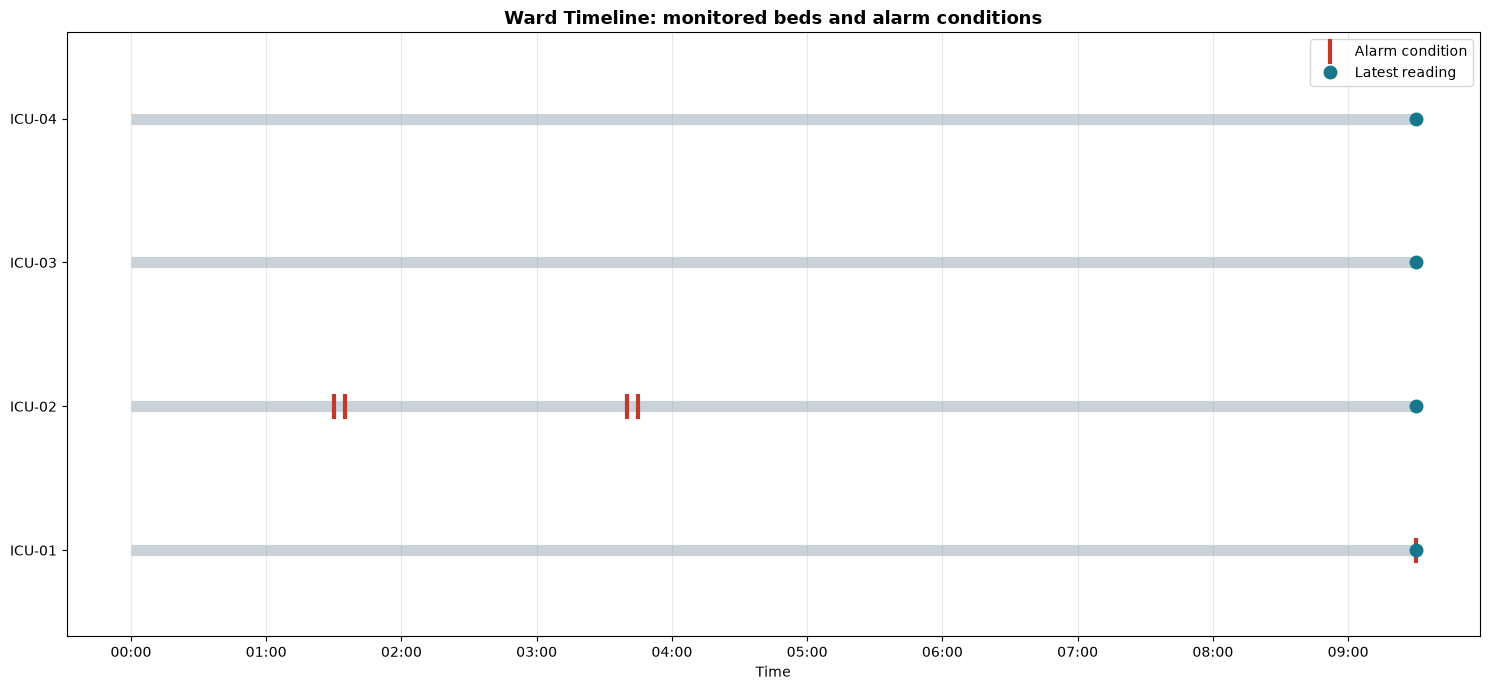

In [10]:
def plot_ward_timeline(df, status=None, figsize=(15, 7)):
    """One row per bed, time along the x axis, alarm conditions shaded.

    A single view showing the state of every monitored patient at a glance, so the
    bed that needs attention is obvious without reading five separate charts.
    """
    beds = sorted(df['bed_id'].unique())
    fig, ax = plt.subplots(figsize=figsize)

    # Thresholds that would trigger a bedside alarm
    def alarm_mask(g):
        return ((g['spo2'] < 92) | (g['heart_rate'] > 120) |
                (g['map_mmhg'] < 65) | (g['resp_rate'] > 25))

    for i, bed in enumerate(beds):
        g = df[df['bed_id'] == bed].sort_values('timestamp')
        y = np.full(len(g), i)

        # The baseline track for this bed
        ax.plot(g['timestamp'], y, '-', color='#c8d2d8', linewidth=8,
                solid_capstyle='butt', zorder=1)

        # Shade the periods where an alarm threshold is breached
        mask = alarm_mask(g).to_numpy()
        if mask.any():
            ax.plot(g['timestamp'][mask], y[mask], '|', color='#c0392b',
                    markersize=18, markeredgewidth=3, zorder=3,
                    label='Alarm condition' if i == 0 else None)

        # Mark the most recent reading
        if len(g):
            ax.plot(g['timestamp'].iloc[-1], i, 'o', color='#16788a',
                    markersize=9, zorder=4,
                    label='Latest reading' if i == 0 else None)

    ax.set_yticks(range(len(beds)))
    ax.set_yticklabels(beds)
    ax.set_ylim(-0.6, len(beds) - 0.4)
    ax.set_xlabel('Time')
    ax.set_title('Ward Timeline: monitored beds and alarm conditions',
                 fontsize=13, fontweight='bold')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax.grid(True, axis='x', alpha=0.3)
    ax.legend(loc='upper right')
    plt.tight_layout()
    return fig


fig = plot_ward_timeline(vitals_df, status_df)
plt.show()


## 7. Plot Channels Over Time

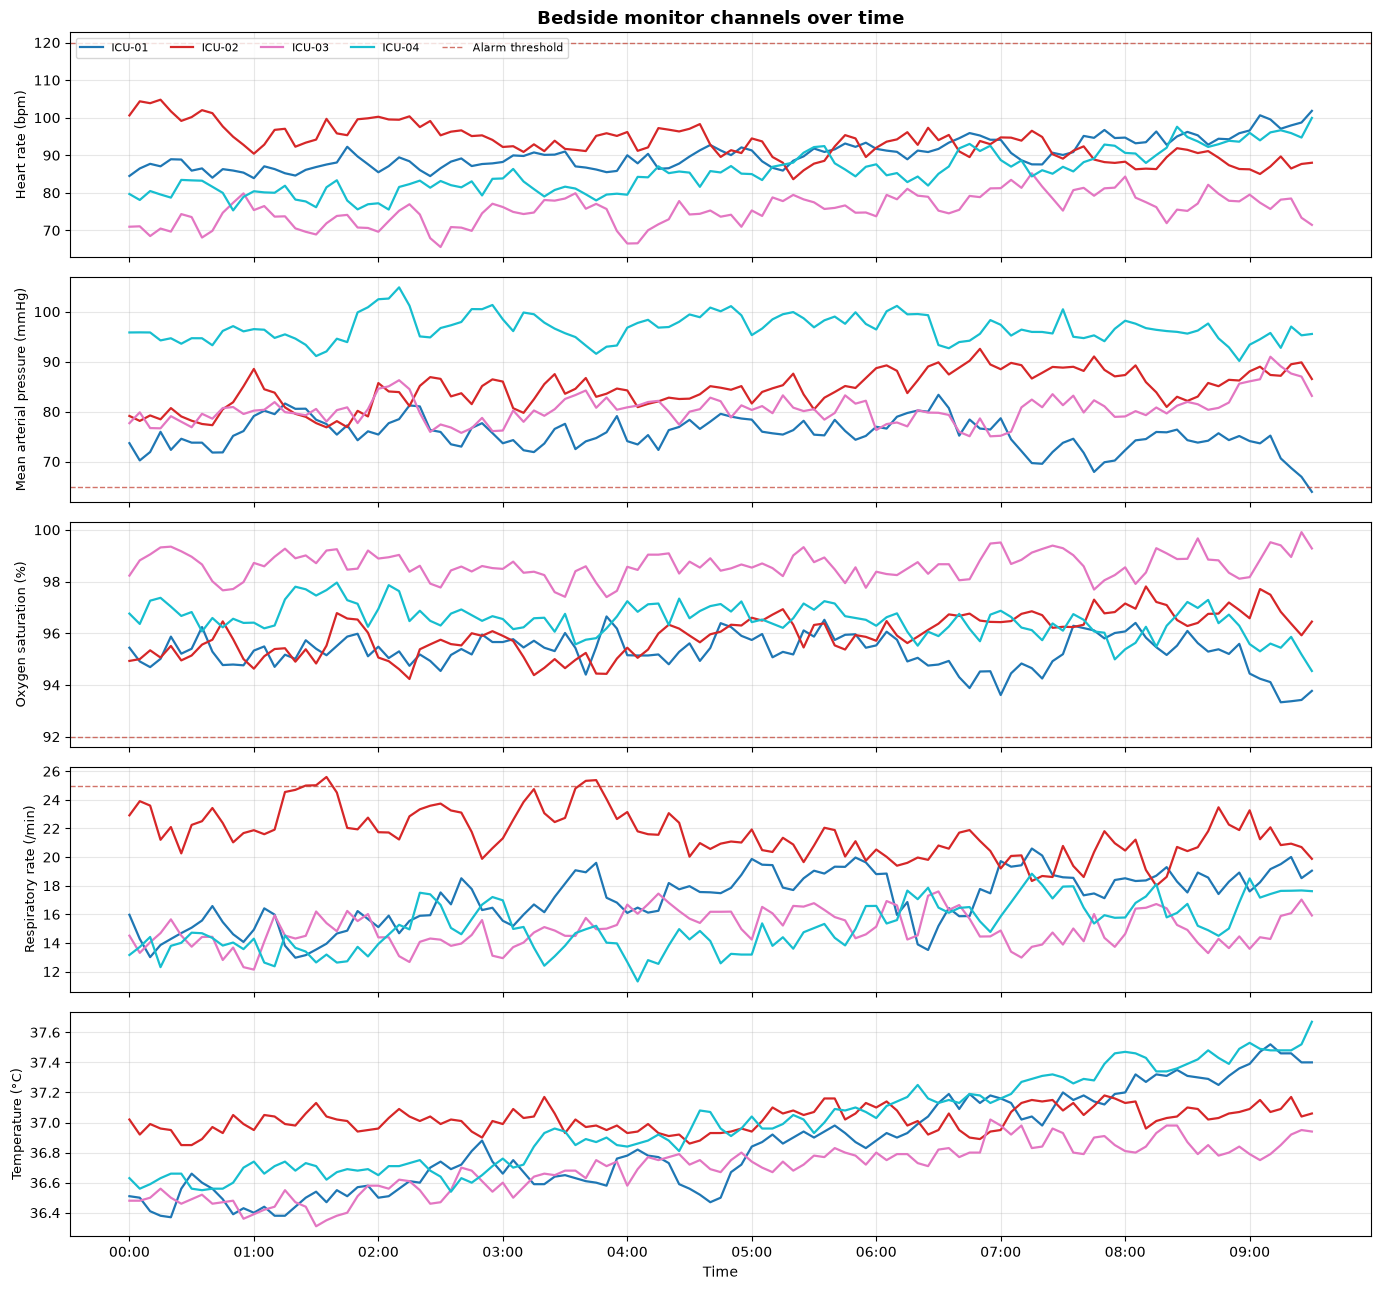

In [11]:
# One panel per channel, one line per bed: the standard way a clinician reads a trend.
CHANNEL_LABELS = {
    'heart_rate': 'Heart rate (bpm)',
    'map_mmhg': 'Mean arterial pressure (mmHg)',
    'spo2': 'Oxygen saturation (%)',
    'resp_rate': 'Respiratory rate (/min)',
    'temp_c': 'Temperature (\u00b0C)',
}
ALARM_LINES = {'heart_rate': 120, 'map_mmhg': 65, 'spo2': 92, 'resp_rate': 25}

beds = sorted(vitals_df['bed_id'].unique())
colors = plt.cm.tab10(np.linspace(0, 1, max(len(beds), 3)))

fig, axes = plt.subplots(len(CHANNEL_LABELS), 1, figsize=(14, 13), sharex=True)
for ax, (ch, label) in zip(axes, CHANNEL_LABELS.items()):
    for bed, color in zip(beds, colors):
        g = vitals_df[vitals_df['bed_id'] == bed].sort_values('timestamp')
        ax.plot(g['timestamp'], g[ch], label=bed, color=color, linewidth=1.6)
    if ch in ALARM_LINES:
        ax.axhline(ALARM_LINES[ch], color='#c0392b', linestyle='--', linewidth=1,
                   alpha=0.7, label='Alarm threshold' if ch == 'heart_rate' else None)
    ax.set_ylabel(label, fontsize=9)
    ax.grid(True, alpha=0.3)

axes[0].set_title('Bedside monitor channels over time', fontsize=13, fontweight='bold')
axes[0].legend(loc='upper left', ncol=len(beds) + 1, fontsize=8)
axes[-1].set_xlabel('Time')
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
plt.tight_layout()
plt.show()


## 8. Save the Collected Data

In [12]:
# Save to CSV, exactly as you would with a real collection run.
timestamp_tag = datetime.now().strftime('%Y%m%d_%H%M%S')

vitals_file = f'ward_vitals_{timestamp_tag}.csv'
vitals_df.to_csv(vitals_file, index=False)
print(f"Wrote {vitals_file}  ({len(vitals_df)} rows)")

if not status_df.empty:
    status_out = status_df.copy()
    # alarms is a list per row; flatten it so the CSV stays readable
    status_out['alarms'] = status_out['alarms'].apply(lambda a: '|'.join(a) if a else '')
    status_file = f'ward_status_{timestamp_tag}.csv'
    status_out.to_csv(status_file, index=False)
    print(f"Wrote {status_file}  ({len(status_out)} rows)")

print("\nIn a real deployment these files hold protected health information.")
print("They would be written to encrypted storage with access logging, never to a laptop.")


Wrote ward_vitals_20261003_102635.csv  (460 rows)
Wrote ward_status_20261003_102635.csv  (76 rows)

In a real deployment these files hold protected health information.
They would be written to encrypted storage with access logging, never to a laptop.


## 9. Disconnect

In [13]:
collector.disconnect()
print(f"Connected: {collector.connected}")


Disconnected.
Connected: False


## 10. Reusable Collection Function

In [14]:
def collect_vitals(duration_seconds=10, beds=NUM_BEDS, speedup=SPEEDUP,
                   topics=None, save_to_file=False):
    """Run one complete collection cycle and return the two DataFrames.

    Wraps everything above so a downstream notebook can pull a fresh ward in one call.
    """
    topics = topics or [TOPIC_VITALS, TOPIC_STATUS]

    c = VitalsCollector(beds=beds, speedup=speedup)
    c.connect()
    c.subscribe(*topics)
    c.collect(seconds=duration_seconds)
    c.disconnect()

    v, s = c.vitals_df(), c.status_df()

    if save_to_file and not v.empty:
        tag = datetime.now().strftime('%Y%m%d_%H%M%S')
        v.to_csv(f'ward_vitals_{tag}.csv', index=False)
        print(f"Saved ward_vitals_{tag}.csv")

    return v, s


# Quick demonstration
demo_vitals, demo_status = collect_vitals(duration_seconds=4)
print(f"\nDemo run: {len(demo_vitals)} vitals rows from "
      f"{demo_vitals['bed_id'].nunique() if not demo_vitals.empty else 0} beds")


Connected to simulated:1883
Subscribed: ward/bed/+/vitals
Subscribed: ward/bed/+/status


Collected 156 vitals, 24 status messages.
Disconnected.

Demo run: 156 vitals rows from 4 beds


## 11. Quick Reference

### The MQTT pattern

| Step | Method | Notes |
|---|---|---|
| Connect | `client.connect(host, port, keepalive)` | `rc=0` in `on_connect` means success |
| Subscribe | `client.subscribe(topic)` | `+` matches one level, `#` matches all remaining |
| Receive | `on_message(client, userdata, msg)` | Runs on the network thread. Buffer, do not block. |
| Run | `loop_start()` / `loop_stop()` | Background thread; `loop_forever()` blocks instead |
| Disconnect | `client.disconnect()` | Always clean up |

### Topic wildcards

| Pattern | Matches |
|---|---|
| `ward/bed/ICU-01/vitals` | that one bed's vitals |
| `ward/bed/+/vitals` | every bed's vitals |
| `ward/bed/ICU-01/#` | everything for that bed |

### Moving to a real gateway

1. Replace `SimulatedMonitorClient(...)` with `paho.mqtt.client.Client()`.
2. Point `BROKER_HOST` at the device gateway and use port 8883.
3. Add `client.tls_set(...)` and credentials. Never send patient data unencrypted.
4. Confirm the gateway's actual topic structure and payload schema; they vary by vendor.
5. Get information-governance approval before connecting to anything carrying real data.

### Things that bite you on a real feed

- **Out-of-order and duplicate messages.** Deduplicate on (bed, timestamp).
- **Gaps.** A disconnected lead produces silence, not a null. Absence is data.
- **Artefact.** A displaced sensor reads plausibly but wrongly. Physiological limits catch some of it.
- **Clock skew.** Device clocks drift. Prefer gateway-stamped time where you have it.


## Next Steps

Now that the stream is a DataFrame, the rest of the course applies directly:

- **[Isolation Forest](../session_2_classical_ml/s2_13_isolation_forest_tutorial.ipynb)** to flag anomalous telemetry in this feed
- **[PCA deterioration scoring](../session_2_classical_ml/s2_10_pca_executive_deterioration_scoring.ipynb)** to compress many channels into one alert score per bed
- **[Vitals trajectory forecasting](../session_3_deep_learning/s3_04_vitals_trajectory_prediction.ipynb)** to predict where a patient is heading
- **[Time series forecasting](../session_3_deep_learning/s3_06_ttm_vitals_forecasting.ipynb)** for a multi-channel horizon forecast

A streaming source plus one of these models is the shape of most real early-warning systems.
